In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [100]:
df=pd.read_csv('exam.csv')
df.head(5)

,study_hours,pass_fail
0,0.50,0
1,0.75,0
2,1.00,0
3,1.25,0
4,1.50,0


In [101]:
df.shape

(20, 2)

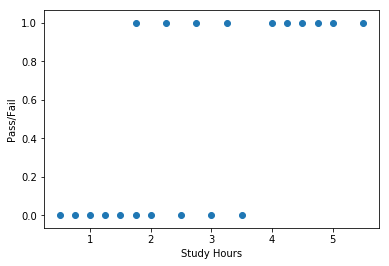

In [102]:
x, y =df[['study_hours']].values, df[['pass_fail']].values

plt.xlabel('Study Hours')
plt.ylabel('Pass/Fail')
plt.scatter(x,y)
plt.show()

In [103]:
x_train,x_test, y_train, y_test = train_test_split(x,y,test_size=0.25)

In [104]:
def standard_scaler(x_train, x_test):
    mean = x_train.mean(axis=0)
    std= x_train.std(axis=0)
    x_train = (x_train - mean) / std
    x_test = (x_test - mean) / std
    return x_train, x_test

In [105]:
x_train, x_test=standard_scaler(x_train, x_test)


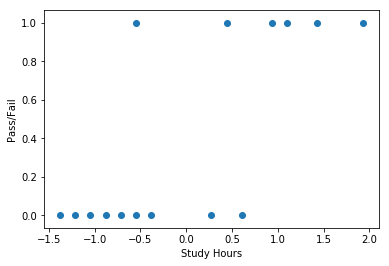

In [106]:
plt.xlabel('Study Hours')
plt.ylabel('Pass/Fail')
plt.scatter(x_train,y_train)
plt.show()

# Logistic Regression

### initialize parameters

In [125]:
eta=0.01
epoch=10000

In [108]:
x_train = np.hstack((np.ones((len(x_train),1)),x_train))
x_train.shape

(15, 2)

In [109]:
m=1 #تعداد فیچر هامون که اینجا یدونه اس
w=np.random.randn(m+1,1)
w.shape

(2, 1)

### defining functions

In [110]:
def regression(x,w):
    return x@w

In [111]:
def sigmoid(u):
    return 1/(1 + np.exp(-u))

In [112]:
def bce(y,yh):
    return -np.mean(y*np.log(yh) + (1-y)*np.log(1-yh))

In [113]:
def grad(x,y,yh):
    return (1/len(x))*x.T@(yh-y)

In [120]:
def grad_descent(w,eta,grad):
    return w-(eta*grad)

In [121]:
def logistic_regression(x,y,w,eta):
    u=regression(x,w)
    yh=sigmoid(u)
    loss=bce(y,yh)
    gd=grad(x,y,yh)
    uw=grad_descent(w,eta,gd)
    return uw, loss
    

### Train

In [122]:
error_hist = []

In [126]:
for i in range(epoch):
    w,loss=logistic_regression(x_train,y_train,w,eta)
    error_hist.append(loss)

print(w,loss)

[[-0.67646593]
 [ 2.28904311]] 0.3617118221525418


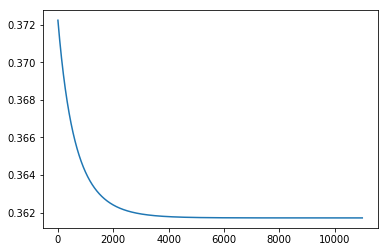

In [127]:
plt.plot(error_hist)

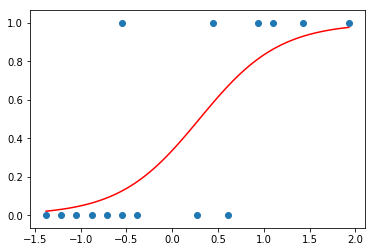

In [128]:
x_plot = np.linspace(x_train[:, 1].min(), x_train[:, 1].max(), 100)
y_plot = sigmoid(w[0] + w[1] * x_plot)

plt.scatter(x_train[:, 1], y_train)
plt.plot(x_plot, y_plot, color='red')
plt.show()